# 02 — RUL & Fault Classification (NASA/IMS)
Leave-One-Set-Out CV over `case1/2/3` throughout. No random splits.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import confusion_matrix, classification_report, mean_absolute_error
from xgboost import XGBRegressor

DATA = Path(".")                       # folder holding the three CSVs
FEATS = ["RMS", "Peak", "Kurtosis", "Skew", "Crest", "band_10_1000", "band_1000_3000", "band_3000_6000", "band_6000_9500",
         "BPFO_rms", "BPFI_rms", "BSF_rms"]   # from extract_features.py (_v2 CSVs)
FAULT = {"case1": "BPFI", "case2": "BPFO", "case3": "BPFO"}   # case1: B3, case2: B1, case3: B3
HEALTHY_FRAC, ANOM_TRAIN_FRAC = 0.30, 0.20
K_IQR, SMOOTH, WIN, SEED = 3, 5, 10, 0
logo = LeaveOneGroupOut()

## 1. Data preparation & ground truth
- `state`: first 30 % healthy; afterwards degrading when 5-file rolling-median RMS > baseline median + 3·IQR (baseline = first 30 %). Latched (once degrading, stays degrading).
- `RUL_percent`: 100 until onset, then linear to 0 at the final file.
- `*_n` columns: features divided by each set's own healthy-baseline median (first 20 %) to remove per-sensor scale offsets.

In [2]:
def find(i):
    return next(p for p in DATA.iterdir() if p.name.lower() == f"case{i}_features_v2.csv")

def prep(d):
    n = len(d); h = int(HEALTHY_FRAC * n); idx = np.arange(n)
    b = d["RMS"].iloc[:h]; q1, q3 = b.quantile([.25, .75])
    thr = b.median() + K_IQR * (q3 - q1)
    exceed = (d["RMS"].rolling(SMOOTH, min_periods=1).median().values > thr) & (idx >= h)
    state = np.maximum.accumulate(exceed).astype(int)
    onset = int(state.argmax()) if state.any() else n - 1
    d = d.copy()
    d["file_idx"], d["n_files"], d["life"] = idx, n, idx / (n - 1)
    d["onset_idx"], d["state"] = onset, state
    d["RUL_percent"] = np.where(idx <= onset, 100.0, 100.0 * (n - 1 - idx) / max(n - 1 - onset, 1))
    base = d[FEATS].iloc[:int(ANOM_TRAIN_FRAC * n)].median()
    d[[f + "_n" for f in FEATS]] = d[FEATS] / base.values
    return d

df = pd.concat([prep(pd.read_csv(find(i)).assign(set_id=f"case{i}")) for i in (1, 2, 3)], ignore_index=True)
df["fault"] = df["set_id"].map(FAULT)
FN = [f + "_n" for f in FEATS]
summ = df.groupby("set_id").agg(n=("state", "size"), onset=("onset_idx", "first"), degraded=("state", "mean"), fault=("fault", "first"))
summ["onset_pct"] = (100 * summ["onset"] / summ["n"]).round(1)
print(summ)

           n  onset  degraded fault  onset_pct
set_id                                        
case1   2156   1847  0.143321  BPFI       85.7
case2    984    534  0.457317  BPFO       54.3
case3   6324   5191  0.179159  BPFO       82.1


## 2. Task 1 — Health-state classification
### 2a. Unsupervised detector (Isolation Forest), fit per set on first 20 % only
Alarm = 5 consecutive anomalous files, threshold = 1 % quantile of healthy scores. (Smoothing / stricter variants were tried and detected case 2 worse, so they were reverted.) Detection lag = alarm index − labelled onset (files and % of lifetime).

        onset_idx  alarm_idx  lag_files  lag_pct_life  alarm_pct_life  healthy_zone_false_flag_rate  post_onset_flag_rate
set_id                                                                                                                   
case1        1847       1788        -59         -2.74           82.93                         0.019                 0.974
case2         534        639        105         10.67           64.94                         0.000                 0.824
case3        5191       6015        824         13.03           95.11                         0.000                 0.261


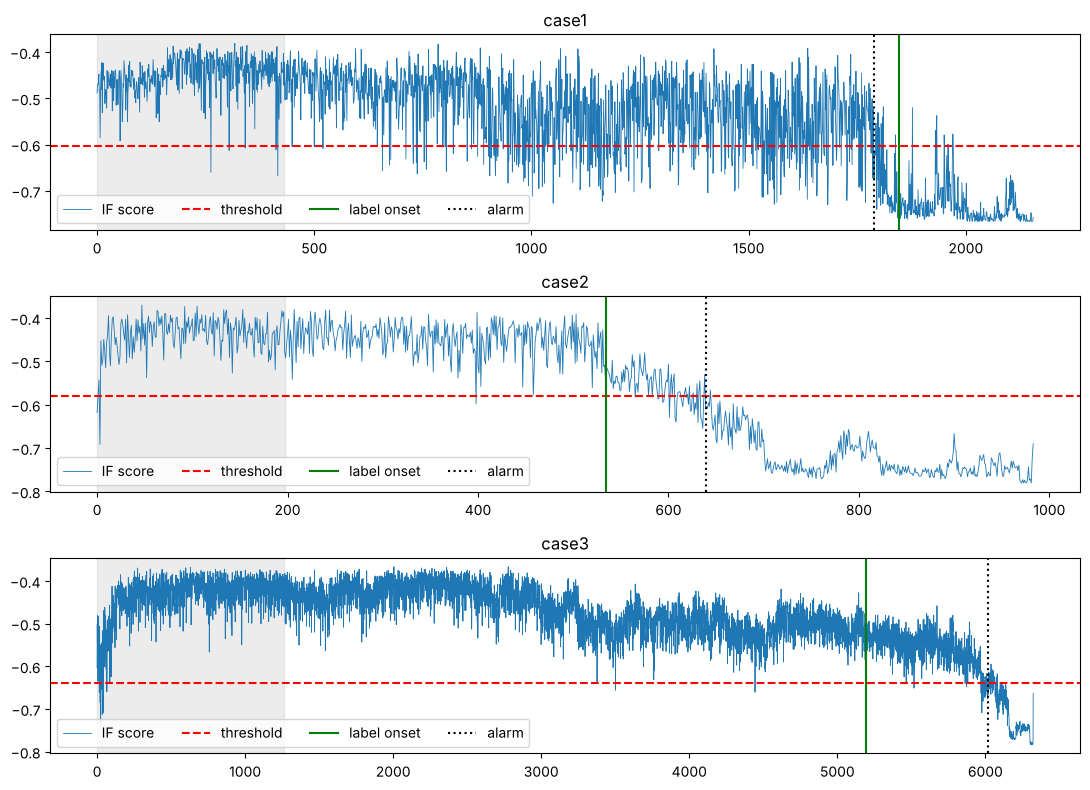

In [3]:
PERSIST, QUANT = 5, 0.01
rows, scores = [], {}
for sid, d in df.groupby("set_id"):
    n, h = len(d), int(ANOM_TRAIN_FRAC * len(d))
    sc = StandardScaler().fit(d[FN].iloc[:h])
    X = sc.transform(d[FN])
    m = IsolationForest(n_estimators=300, random_state=SEED).fit(X[:h])
    s = m.score_samples(X)                              # lower = more anomalous
    thr = np.quantile(s[:h], QUANT)
    flag = s < thr
    run = pd.Series(flag).astype(int).rolling(PERSIST).sum().values == PERSIST
    run[:h] = False                                     # alarms only after training window
    alarm = int(np.argmax(run)) - PERSIST + 1 if run.any() else None
    onset = int(d["onset_idx"].iloc[0])
    scores[sid] = (s, thr, alarm, onset)
    rows.append(dict(set_id=sid, onset_idx=onset, alarm_idx=alarm,
                     lag_files=None if alarm is None else alarm - onset,
                     lag_pct_life=None if alarm is None else round(100 * (alarm - onset) / n, 2),
                     alarm_pct_life=None if alarm is None else round(100 * alarm / n, 2),
                     healthy_zone_false_flag_rate=round(float(flag[h:int(HEALTHY_FRAC * n)].mean()), 3),
                     post_onset_flag_rate=round(float(flag[onset:].mean()), 3)))
print(pd.DataFrame(rows).set_index("set_id").to_string())

fig, ax = plt.subplots(3, 1, figsize=(11, 8))
for a, (sid, (s, thr, alarm, onset)) in zip(ax, scores.items()):
    a.plot(s, lw=.6, label="IF score"); a.axhline(thr, c="r", ls="--", label="threshold")
    a.axvline(onset, c="g", label="label onset")
    if alarm is not None: a.axvline(alarm, c="k", ls=":", label="alarm")
    a.axvspan(0, ANOM_TRAIN_FRAC * len(s), color="grey", alpha=.15); a.set_title(sid); a.legend(loc="lower left", ncol=4)
plt.tight_layout(); plt.show()

### 2b. Supervised baseline (Random Forest), Leave-One-Set-Out
Note: `state` is derived from RMS, so this measures reproducibility of the label from the feature set, not independent ground truth.

In [4]:
y, g = df["state"].values, df["set_id"].values
NO_RMS = [f for f in FN if f not in ("RMS_n", "Peak_n", "Crest_n") and not f.startswith("band_")]   # drop RMS and RMS-like amplitude features
for name, cols in [("with RMS (circular, label comes from RMS)", FN), ("WITHOUT RMS (honest)", NO_RMS)]:
    pred = np.zeros(len(df), int)
    for tr, te in logo.split(df, y, g):
        pred[te] = RandomForestClassifier(300, class_weight="balanced", n_jobs=-1, random_state=SEED).fit(df.loc[tr, cols], y[tr]).predict(df.loc[te, cols])
    print("=====", name, "\n", confusion_matrix(y, pred), "\n", classification_report(y, pred, target_names=["healthy", "degraded"], digits=3))
    for sid in ["case1", "case2", "case3"]:
        mk = g == sid
        print(sid, "left out | acc", round((pred[mk] == y[mk]).mean(), 3), "| CM", confusion_matrix(y[mk], pred[mk], labels=[0, 1]).tolist())

===== with RMS (circular, label comes from RMS) 
 [[7481   91]
 [ 619 1273]] 
               precision    recall  f1-score   support

     healthy      0.924     0.988     0.955      7572
    degraded      0.933     0.673     0.782      1892

    accuracy                          0.925      9464
   macro avg      0.928     0.830     0.868      9464
weighted avg      0.926     0.925     0.920      9464

case1 left out | acc 0.976 | CM [[1800, 47], [4, 305]]
case2 left out | acc 0.894 | CM [[534, 0], [104, 346]]
case3 left out | acc 0.912 | CM [[5147, 44], [511, 622]]


===== WITHOUT RMS (honest) 
 [[6950  622]
 [1066  826]] 
               precision    recall  f1-score   support

     healthy      0.867     0.918     0.892      7572
    degraded      0.570     0.437     0.495      1892

    accuracy                          0.822      9464
   macro avg      0.719     0.677     0.693      9464
weighted avg      0.808     0.822     0.812      9464

case1 left out | acc 0.715 | CM [[1240, 607], [8, 301]]
case2 left out | acc 0.811 | CM [[523, 11], [175, 275]]
case3 left out | acc 0.86 | CM [[5187, 4], [883, 250]]


## 3. Task 2 — Fault diagnosis
Ratio = BPFO_rms / BPFI_rms, smoothed (rolling mean over 50 files) and divided by the set's own healthy ratio → `ratio_rel`. >1 means BPFO grew faster, <1 means BPFI grew faster.
Rule: `ratio_rel > 1` → BPFO else BPFI. Evaluated on degraded files.
Linear model: logistic regression on log(BPFO_rms_n), log(BPFI_rms_n) (smoothed), each set weighted equally. Fold undefined if training sets hold one class only (case1 left out).

left out case2 | coef (log BPFO, log BPFI) = [-0.05 -0.15] classes ['BPFI' 'BPFO']
left out case3 | coef (log BPFO, log BPFI) = [ 0.05 -0.18] classes ['BPFI' 'BPFO']
       truth  n_degraded  rule_acc  median_ratio_rel  linear_acc
set_id                                                          
case1   BPFI         309     1.000             0.803         NaN
case2   BPFO         450     1.000             1.266       0.673
case3   BPFO        1133     0.147             0.957       0.814

Rule, all degraded files:
               precision    recall  f1-score   support

        BPFI      0.242     1.000     0.390       309
        BPFO      1.000     0.389     0.560      1583

    accuracy                          0.489      1892
   macro avg      0.621     0.695     0.475      1892
weighted avg      0.876     0.489     0.532      1892

Linear LOSO (defined folds only):
               precision    recall  f1-score   support

        BPFI      0.000     0.000     0.000         0
        BP

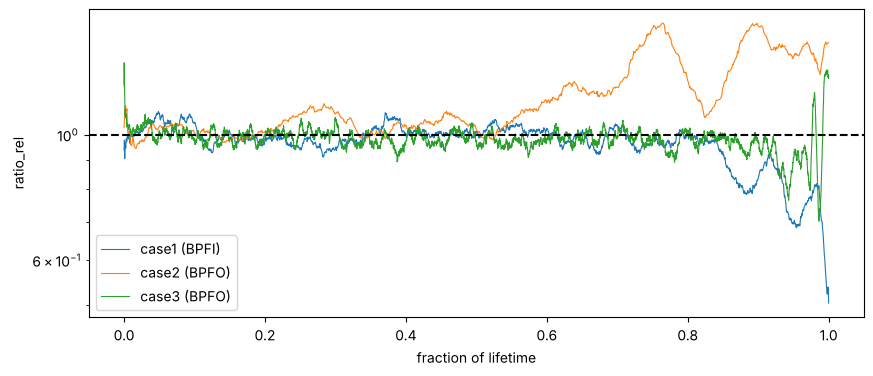

In [5]:
RW = 50
sm = df.groupby("set_id")[["BPFO_rms", "BPFI_rms"]].transform(lambda c: c.rolling(RW, min_periods=1).mean())
df["ratio"] = df["BPFO_rms"] / df["BPFI_rms"]
r = sm["BPFO_rms"] / sm["BPFI_rms"]
h0 = df["file_idx"] < (ANOM_TRAIN_FRAC * df["n_files"])
df["ratio_rel"] = r / r[h0].groupby(df["set_id"]).transform("median").reindex(df.index).fillna(r[h0].groupby(df["set_id"]).median().reindex(df["set_id"]).set_axis(df.index))
df["lb"], df["li"] = np.log(sm["BPFO_rms"] / df.groupby("set_id")["BPFO_rms"].transform(lambda c: c.iloc[:int(ANOM_TRAIN_FRAC*len(c))].median())), \
                     np.log(sm["BPFI_rms"] / df.groupby("set_id")["BPFI_rms"].transform(lambda c: c.iloc[:int(ANOM_TRAIN_FRAC*len(c))].median()))
dg = df[df["state"] == 1].reset_index(drop=True)
dg["rule"] = np.where(dg["ratio_rel"] > 1.0, "BPFO", "BPFI")
dg["linear"] = None
for tr, te in logo.split(dg, groups=dg["set_id"]):
    ytr = dg.loc[tr, "fault"]
    if ytr.nunique() < 2:
        continue
    w = 1.0 / dg.loc[tr, "set_id"].map(dg.loc[tr, "set_id"].value_counts())
    lm = LogisticRegression(class_weight="balanced", max_iter=1000).fit(dg.loc[tr, ["lb", "li"]], ytr, sample_weight=w.values)
    dg.loc[te, "linear"] = lm.predict(dg.loc[te, ["lb", "li"]])
    print(f"left out {dg.loc[te,'set_id'].iloc[0]} | coef (log BPFO, log BPFI) =", lm.coef_.round(2).ravel(), "classes", lm.classes_)

res = []
for sid, d in dg.groupby("set_id"):
    res.append(dict(set_id=sid, truth=d["fault"].iloc[0], n_degraded=len(d), rule_acc=(d["rule"] == d["fault"]).mean(),
                    median_ratio_rel=d["ratio_rel"].median(),
                    linear_acc=(d["linear"] == d["fault"]).mean() if d["linear"].notna().any() else np.nan))
print(pd.DataFrame(res).set_index("set_id").round(3).to_string())
ok = dg["linear"].notna()
print("\nRule, all degraded files:\n", classification_report(dg["fault"], dg["rule"], digits=3, zero_division=0))
print("Linear LOSO (defined folds only):\n", classification_report(dg.loc[ok, "fault"], dg.loc[ok, "linear"], digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(10, 4))
for sid, d in df.groupby("set_id"):
    ax.semilogy(d["life"], d["ratio_rel"], lw=.8, label=f"{sid} ({FAULT[sid]})")
ax.axhline(1, c="k", ls="--"); ax.set_xlabel("fraction of lifetime"); ax.set_ylabel("ratio_rel"); ax.legend(); plt.show()

## 4. Task 3 — RUL estimation
Trailing 10-file rolling mean/std of each normalised feature (computed within each set). Models: Ridge, Random Forest (baselines), XGBoost (advanced). Target `RUL_percent`; predictions clipped to [0, 100].

model     RandomForest  Ridge  XGBoost   metric
left_out                                       
case1             7.71   7.36     4.96  MAE_all
case2             9.57  12.95    11.33  MAE_all
case3             8.21   9.49    10.81  MAE_all
model     RandomForest  Ridge  XGBoost        metric
left_out                                            
case1            22.26  41.52    16.40  MAE_degraded
case2            20.90  26.39    24.66  MAE_degraded
case3            18.43  31.39    16.80  MAE_degraded
Mean over folds:
               MAE_all  MAE_degraded
model                              
RandomForest     8.49         20.53
Ridge            9.93         33.10
XGBoost          9.03         19.29


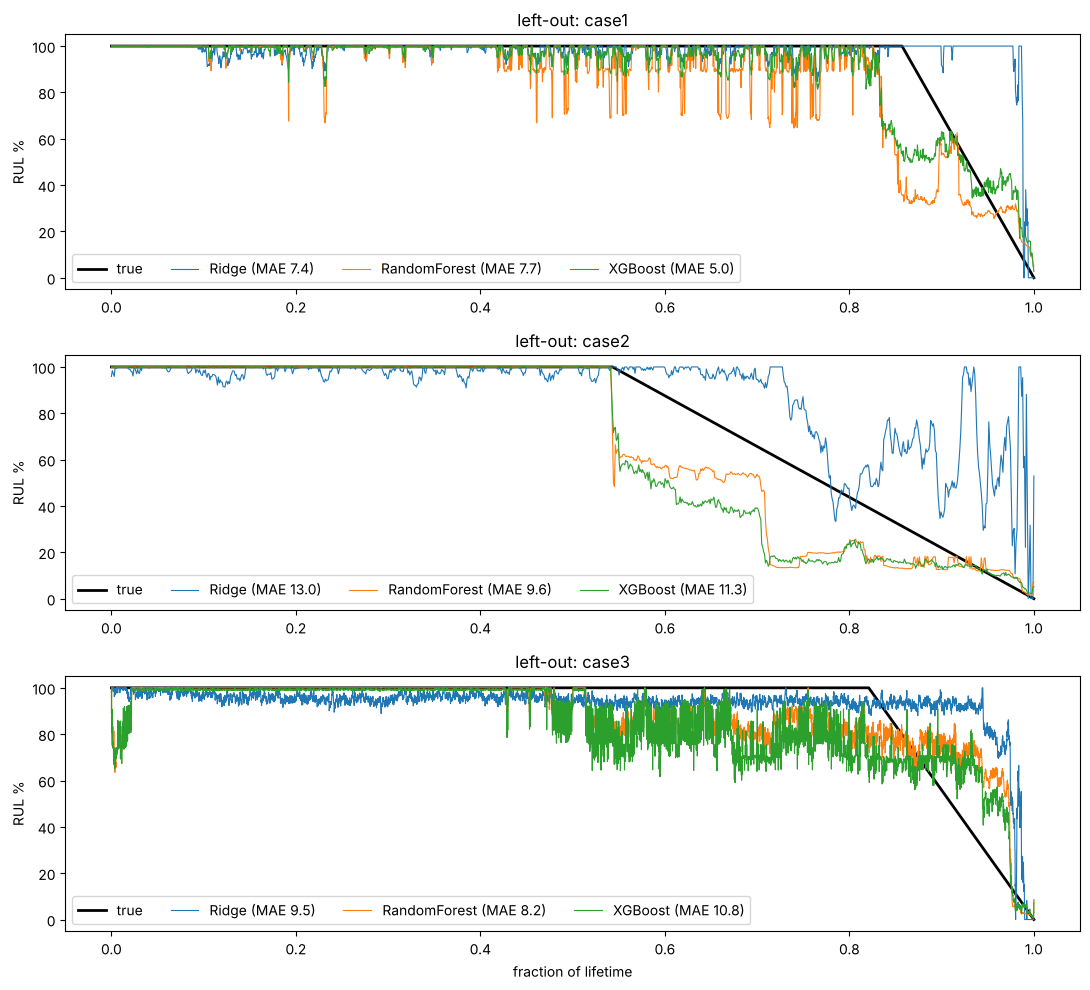

In [6]:
roll = df.groupby("set_id")[FN].rolling(WIN, min_periods=1)
RM = roll.mean().reset_index(level=0, drop=True).add_suffix("_rmean")
RS = roll.std().reset_index(level=0, drop=True).fillna(0).add_suffix("_rstd")
def slope(c):                                              # trend over last WIN files
    t = np.arange(WIN) - (WIN - 1) / 2
    return c.rolling(WIN).apply(lambda v: (t * (v - v.mean())).sum() / (t ** 2).sum(), raw=True)
SL = df.groupby("set_id")[FN].transform(slope).fillna(0).add_suffix("_slope")
X = pd.concat([df[FN], RM, RS, SL], axis=1).loc[df.index]
yr = df["RUL_percent"].values
models = {
    "Ridge": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "RandomForest": lambda: RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "XGBoost": lambda: XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=.8, colsample_bytree=.8, random_state=SEED, n_jobs=-1),
}
oof = {k: np.zeros(len(df)) for k in models}
mae = []
for tr, te in logo.split(X, yr, g):
    sid = g[te][0]
    for k, mk in models.items():
        oof[k][te] = np.clip(mk().fit(X.iloc[tr], yr[tr]).predict(X.iloc[te]), 0, 100)
        mae.append(dict(left_out=sid, model=k, MAE_all=mean_absolute_error(yr[te], oof[k][te]),
                        MAE_degraded=mean_absolute_error(yr[te][df["state"].values[te] == 1], oof[k][te][df["state"].values[te] == 1])))
M = pd.DataFrame(mae)
print(M.pivot(index="left_out", columns="model", values="MAE_all").assign(metric="MAE_all").round(2).to_string())
print(M.pivot(index="left_out", columns="model", values="MAE_degraded").assign(metric="MAE_degraded").round(2).to_string())
print("Mean over folds:\n", M.groupby("model")[["MAE_all", "MAE_degraded"]].mean().round(2))

fig, ax = plt.subplots(3, 1, figsize=(11, 10))
for a, sid in zip(ax, ["case1", "case2", "case3"]):
    mk = g == sid
    a.plot(df.loc[mk, "life"], yr[mk], "k", lw=2, label="true")
    for k in models:
        a.plot(df.loc[mk, "life"], oof[k][mk], lw=.8, label=f"{k} (MAE {mean_absolute_error(yr[mk], oof[k][mk]):.1f})")
    a.set_title(f"left-out: {sid}"); a.set_ylabel("RUL %"); a.legend(ncol=4, loc="lower left")
ax[-1].set_xlabel("fraction of lifetime"); plt.tight_layout(); plt.show()